## Step 1: Extract and Clean Country Information

In [2]:
import pandas as pd 

df = pd.read_csv("../../data/processed/netflix_cleaned.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min


In [3]:
print(df["country"].head(10))
print("Missing country values:",df["country"].isna().sum())

0     United States
1            France
2     United States
3            Brazil
4     United States
5    United Kingdom
6     United States
7             India
8           Germany
9             India
Name: country, dtype: str
Missing country values: 0


In [4]:
# Check the number of unique country entries
print("Unique country entries:",df["country"].nunique())

# Display the 10 most frequent country entries
print(df["country"].value_counts().head(10))

Unique country entries: 86
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


### Points noted from the above output:
Dataset has 86 unique country entries, where the United States appears most frequently, followed by India and the United Kingdom.

One thing to note "Not Given" appears 287 times, so we should exclude it from country ranking. 

In [5]:
# Remove extra spaces and standardize missing values
df["country"]=df["country"].str.strip()
df["country"]= df["country"].replace(["Not Given", ""], pd.NA)

print("Missing country values:", df["country"].isna().sum())

Missing country values: 287


## Step 2: Calculate content count by country.

In [6]:
# Count records for each country
country_counts = df["country"].dropna().value_counts()

print("Total country-associated records:", country_counts.sum())
print("\nTop 10 countries:")
print(country_counts.head(10)) 

Total country-associated records: 8503

Top 10 countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


## Step 3: Identify Top Content-Producing Countries

In [7]:
# Select the top 10 countries
top_10_countries = country_counts.head(10)

# Display the ranking
print(top_10_countries)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


In [11]:
# Create a ranked table
country_ranking = top_10_countries.reset_index()
country_ranking.columns = ["Country", "Content Count"]
country_ranking.insert(
    0, "Rank", range(1, len(country_ranking) + 1)
)

print(country_ranking)

   Rank         Country  Content Count
0     1   United States           3240
1     2           India           1057
2     3  United Kingdom            638
3     4        Pakistan            421
4     5          Canada            271
5     6           Japan            259
6     7     South Korea            214
7     8          France            213
8     9           Spain            182
9    10          Mexico            138


## Step 4 — Create charts and rankings

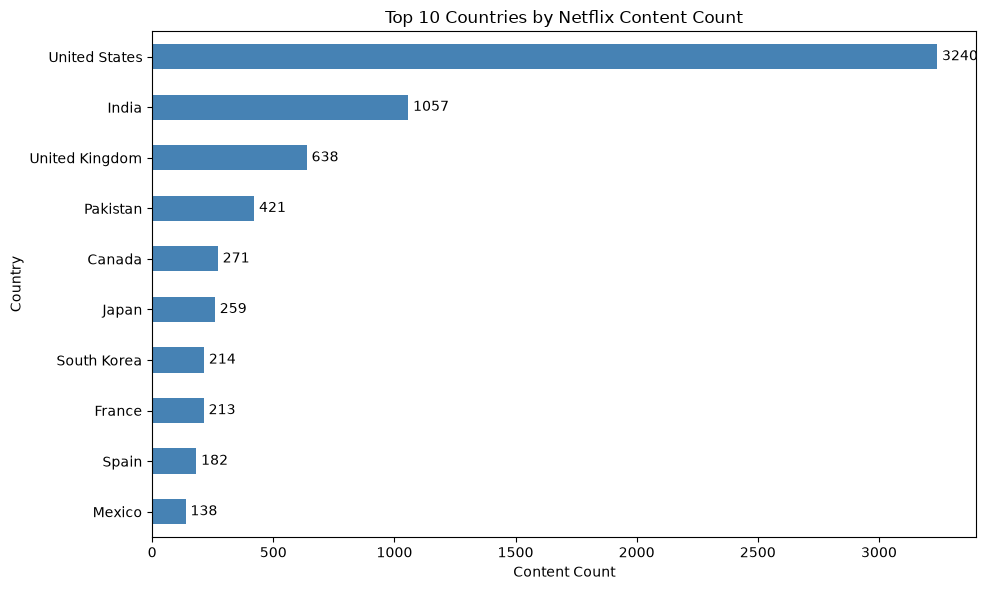

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,6))

top_10_countries.sort_values().plot(
    kind= "barh",
    ax=ax,
    color= "steelblue"
)

for bar in ax.patches:
    ax.text(
        bar.get_width() + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center"
    )

plt.title("Top 10 Countries by Netflix Content Count")
plt.xlabel("Content Count")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    "top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 5: Generate Business Insights

Analyze the country-wise content counts to identify leading countries and compare their contributions.

In [23]:
# Get the highest-ranked country
top_country = country_counts.index[0]
top_count = country_counts.iloc[0]

# Get India's count
india_count = country_counts.get("India", 0)

# Compare India's count with the top country
india_percentage = (india_count / top_count) * 100

print("Top country:", top_country)
print("Top country content count:", top_count)
print("India content count:", india_count)
print(f"India's count compared with the top country: {india_percentage:.2f}%")

Top country: United States
Top country content count: 3240
India content count: 1057
India's count compared with the top country: 32.62%


### Key Business Insights

1. **Leading country:** The United States ranks first, with 3,240 country records in the cleaned dataset.
2. **India's position:** India ranks second, with 1,057 records.
3. **Content distribution:** The United States has substantially more listed records than any other country in the top 10.
4. **Regional representation:** The top 10 includes countries from Asia, Europe, North America, and other regions, indicating a geographically varied catalog.

**Data limitation:** These findings describe the current cleaned dataset. They should not be interpreted as definitive measures of Netflix's original production output because missing and potentially transformed country information may affect the counts.